Gli array hanno la stessa lunghezza:  True
Incertezze maggiori di zero:  True
Posizioni ordinate:  False
Numero di punti: 201
Intervallo di x:  -5.0 < x <  5.0
Intervallo di y:  39.798 < y <  440.581
Intervallo di sigma_y:  6.308566 < sigma_y <  20.99002


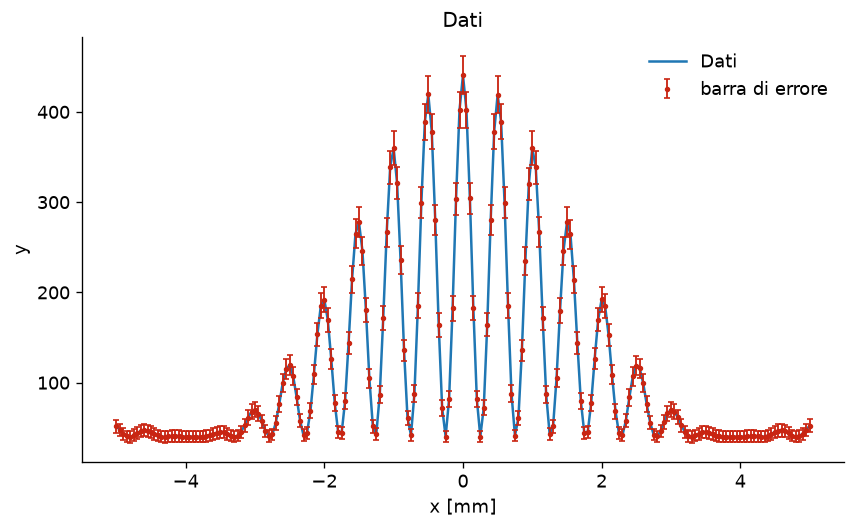

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ARANCIONE = "#E5771C"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

dati = np.genfromtxt("dati_fit_interferenza.csv", delimiter=",", names=True)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print("Gli array hanno la stessa lunghezza: ", len(x)==len(y) and len(y)==len(sigma_y))
#valori finiti (?)
print("Incertezze maggiori di zero: ", sigma_y.all()>0)
print("Posizioni ordinate: ", np.all(x[:-1] < x[:1]))
print("Numero di punti:", len(y))
print("Intervallo di x: ", x.min(), "< x < ", x.max())
print("Intervallo di y: ", y.min(), "< y < ", y.max())
print("Intervallo di sigma_y: ", sigma_y.min(), "< sigma_y < ", sigma_y.max())

fig, ax = plt.subplots()
ax.plot(x, y, label="Dati")
ax.set(xlabel="x [mm]", ylabel="y", title="Dati")
ax.errorbar(x, y, yerr=sigma_y, fmt=".", color=ROSSO, markersize=4.5, capsize=2, elinewidth=1.1, label="barra di errore")
ax.legend()
plt.show()

In [79]:
y_esterni = y[abs(x)>2.5]
B_0 = np.median(y_esterni)
I0_0 = y.max() - B_0
alpha = 0.90 #da stimare
delta = 5.20 #da stimare

def modello (x, alpha, delta, B_0, I0_0):
    E = np.sinc(alpha*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B_0 + I0_0*E*C

lower = [0.0, 0.0, 0.10, 1.0]
upper = [np.inf, np.inf, 3.0, 12.0]

print("Parametro, stima iniziale, bounds, criterio di scelta")
print("B_0: ", B_0, lower[0], " < B_0 < ", upper[0])

print("I0_0: ", I0_0, lower[1], " < I0_0 < ", upper[1])

print("alpha: ", alpha, lower[2], " < alpha < ", upper[2])

print("delta: ", delta, lower[3], " < delta < ", upper[3])

Parametro, stima iniziale, bounds, criterio di scelta
B_0:  43.04575 0.0  < B_0 <  inf
I0_0:  397.53525 0.0  < I0_0 <  inf
alpha:  0.9 0.1  < alpha <  3.0
delta:  5.2 1.0  < delta <  12.0


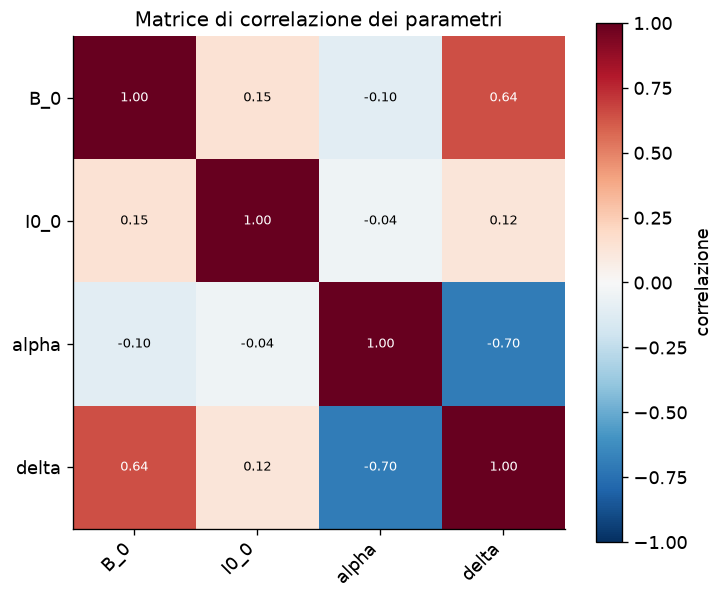

In [80]:
popt, pcov = curve_fit(
modello, x, y,
p0 = np.array([B_0, I0_0, alpha, delta]),
sigma=sigma_y,
absolute_sigma=True,
bounds=(lower, upper),
maxfev=100000
)

parametri = ["B_0", "I0_0", "alpha", "delta"]
errors = np.sqrt(np.diag(pcov))
corr = pcov / np.outer(errors, errors)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(parametri)), parametri, rotation=45, ha="right")
ax.set_yticks(range(len(parametri)), parametri)
ax.set_title("Matrice di correlazione dei parametri")

for row in range(len(parametri)):
    for column in range(len(parametri)):
        color = "white" if abs(corr[row, column]) > 0.55 else "black"
        ax.text(column, row, f"{corr[row, column]:.2f}",
                ha="center", va="center", fontsize=8, color=color)

fig.colorbar(image, ax=ax, label="correlazione")
plt.tight_layout()
plt.show()

In [ ]:
y_fit = modello(x, *popt)

r = y - y_fit #residui
rho = r/sigma_y #pull(residui normalizzati)
chi2 =np.sum(rho**2) #chi quadro
v = len(y) - 4 
chi2_rid = chi2/v


96.34590057075515
